In [25]:
from filemanager import FileManager
fm = FileManager('assets','H04','foo')
# fm.id_block = 'qc'
# fm.timestamp()
# fm.get_filepath('whole','svg')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import loader
importlib.reload(loader)
from loader import load_C05
df=load_C05()
df

,fns,arr_clns,colors,nms,Ts,nano,sz,pxl20nm,k123,phase
0,2HTaSe2_bad_78K097,"[[1.0103092144283519e-13, -3.5913526062327836e...",#9467bd,78K(1),78,160,2048,256,"[[114.0, 523.0], [-530.0, -177.0], [426.0, -34...","[[[-2.0996356884472185, -2.068621200858523, -2..."
5,110K_highres,"[[2.5767310122245523e-13, 4.0635659008804856e-...",#1f77b4,110K(2),110,40,1024,512,"[[26.0, 138.0], [-142.0, -47.0], [116.0, -91.0]]","[[[5.389773847253473, 5.388461139619211, 5.385..."
3,2HTaSe2_ao_115K037,"[[5.857832103672808e-13, 2.382601548993847e-12...",#289E28,115K,115,40,1024,512,"[[31.0, 142.0], [-149.0, -48.0], [118.0, -94.0]]","[[[-5.095307753740863, -5.136761187831822, -5...."
1,2HTaSe2_ap_118K002,"[[-1.5468118784470648e-12, 1.358354867116372e-...",#1f77b4,118K,118,40,512,256,"[[18.0, 142.0], [-145.0, -48.0], [126.0, -94.0]]","[[[-9.837244096340234, -9.792643644973875, -9...."


In [2]:
import imagingPhase.get_phimap as gpm
ua = np.array([-1, 1])*np.pi
dfphase = pd.DataFrame({
'arrfcn':[lambda x:x,gpm.wrap_phase,lambda x: gpm.wrap_phase(3*x)/3],
'cmap':['jet','twilight_shifted','RdBu'],
'clim':[ua*3,ua*(1),ua*(1/3)],
'phaseStr':['monotonic','circular','circular(x3)'],
'ticks':[[-np.pi*3, -np.pi*(2/3), 0, np.pi*(2/3), np.pi*3],
    [-np.pi, -np.pi*(2/3), 0, np.pi*(2/3), np.pi],
    [ -np.pi*(1/3), 0, np.pi*(1/3)]],
'tick_labels':[[r"$-3\pi$", r"$-\frac{2}{3}\pi$" ,"", r"$\frac{2}{3}\pi$" ,r"$3\pi$"],
[r"$-\pi$", r"$-\frac{2}{3}\pi$" ,r"$0$", r"$\frac{2}{3}\pi$" ,r"$\pi$"],
[r"$-\frac{1}{3}\pi$" ,r"$0$", r"$\frac{1}{3}\pi$" ]]
})

imagingPhase package loaded


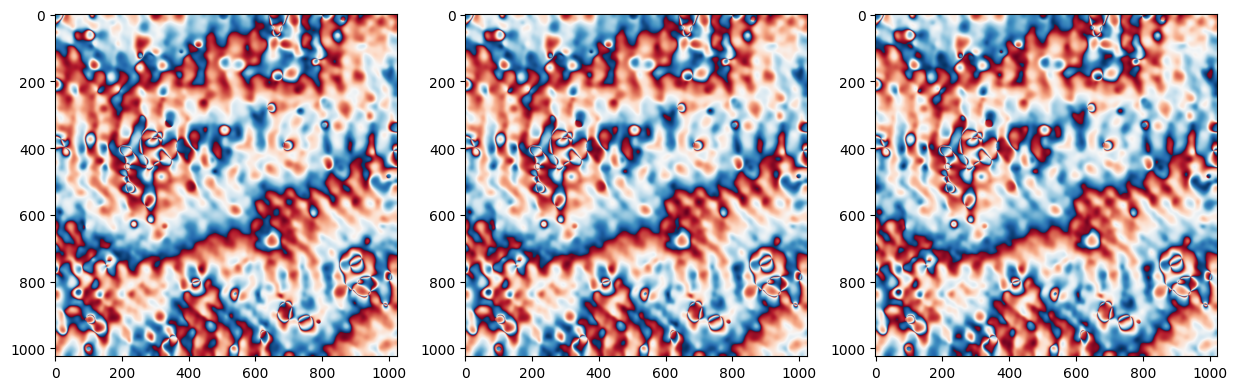

In [29]:
fm.id_block = 'guagefix_fig3'
fm.timestamp()
fm.get_filepath('whole','svg')
idt = 1
iwrap = 2
dfphaseNow = dfphase.iloc[iwrap]
fig,axs = plt.subplots(1,3,figsize=(15,5))
for ik in range(3):
    plt.sca(axs[ik])    
    dt = df['phase'].iloc[idt][0] -0.5 +ik*0.1
    dt_wrap = dfphaseNow['arrfcn'](dt)
    plt.imshow(dt_wrap,cmap=dfphaseNow['cmap'],clim=dfphaseNow['clim'])
plt.savefig(fm.get_filepath('whole','svg'), dpi=300, bbox_inches='tight', pad_inches=0)    

In [12]:
from useful import auto199
a = np.array
xylims = np.array([
    [a([0,64])+920,a([64,0])+920],
    [a([0,128])+100,a([128,0])],
    [a([0,128])+410,a([128,0])+100],
    [a([0,64])+200,a([64,0])+130]
])
xylims.shape

(4, 2, 2)

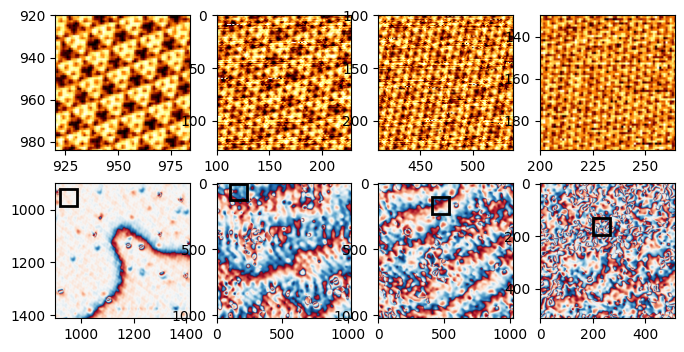

In [21]:
msb,nsb = 2,4
fig,axs = plt.subplots(msb,nsb,figsize=(8,4))
iwrap = 2
dfphaseNow = dfphase.iloc[iwrap]    
ik = 0
for jsb in range(nsb):
    idt = jsb
    dt = df['phase'].iloc[idt][ik]
    dt_wrap = dfphaseNow['arrfcn'](dt)
    axs[1,jsb].imshow(dt_wrap,cmap=dfphaseNow['cmap'],clim=dfphaseNow['clim'])
    img = df['arr_clns'].iloc[idt]        
    axs[0,jsb].imshow(img,cmap='afmhot')
    xlim = xylims[idt,0,:]
    ylim = xylims[idt,1,:]
    rect = patches.Rectangle((xlim[0], ylim[0]), xlim[1]-xlim[0], ylim[1]-ylim[0], linewidth=2, edgecolor='k', facecolor='none')
    axs[1,jsb].add_patch(rect)
    axs[0,jsb].set_xlim(xlim)
    axs[0,jsb].set_ylim(ylim)
    plt.sca(axs[0,jsb])
    auto199()
axs[1,0]    
xlim = np.array([0,512])+900
ylim = np.array([512,0])+900
jsb = 0
axs[1,jsb].set_xlim(xlim)
axs[1,jsb].set_ylim(ylim)
plt.savefig('C05_Fig3_phasemap.svg', format='svg')
